In [1]:
import pandas as pd

path = r"dataset\play_by_play_2024.csv"
cols = ["game_id", "posteam", "play_type", "epa", "success","yards_gained", "down","ydstogo"]
pbp = pd.read_csv(path, usecols=cols)
plays = pbp[pbp["play_type"].isin(["run","pass"])].dropna(subset=["epa"])

print(len(plays))
print(plays.groupby("play_type")["epa"].agg(["count","mean", "std"]).round(3))

35050
           count   mean    std
play_type                     
pass       20007  0.025  1.591
run        15043 -0.009  1.055


In [2]:
from scipy import stats

pass_epa = plays.loc[plays["play_type"] == "pass", "epa"]
run_epa = plays.loc[plays["play_type"] == "run", "epa" ]

t,p = stats.ttest_ind(pass_epa, run_epa, equal_var=False)
print(round(t,3), p)

2.402 0.016313314739993288


In [3]:
diff = pass_epa.mean() - run_epa.mean()
res = stats.ttest_ind(pass_epa, run_epa, equal_var=False)
ci = res.confidence_interval(confidence_level=0.95)
print(round(diff,3), round(ci.low,3), round(ci.high,3))

0.034 0.006 0.062


In [4]:
table = pd.crosstab(plays["play_type"], plays["success"])
print(table)

chi2, p, dof, expected = stats.chi2_contingency(table)
print(round(chi2,3),p)
print(plays.groupby("play_type")["success"].mean().round(3))

success      0.0   1.0
play_type             
pass       11025  8982
run         8618  6425
16.528 4.7935053565979215e-05
play_type
pass    0.449
run     0.427
Name: success, dtype: float64


In [7]:
n1,n2 = len(pass_epa), len(run_epa)
pooled_var = (((n1-1) * pass_epa.var() + (n2-1) * run_epa.var()) / (n1+n2-2))
pooled_std = pooled_var ** 0.5
d = (pass_epa.mean() - run_epa.mean()) / pooled_std
print(round(d,3))

0.025


In [8]:
print(d)

0.02452949562224547


In [9]:
for down in [1,2,3,4]:
    d_plays = plays[plays["down"] == down]
    p_epa = d_plays.loc[d_plays["play_type"] == "pass", "epa"]
    r_epa = d_plays.loc[d_plays["play_type"] == "run", "epa"]
    t,p = stats.ttest_ind(p_epa, r_epa, equal_var=False)
    print(down, len(p_epa), len(r_epa), round(p_epa.mean(), 3), round(r_epa.mean(),3), round(p,4))

1 7205 8116 0.073 -0.065 0.0
2 6859 4758 0.065 -0.01 0.0009
3 5345 1804 -0.085 0.117 0.0
4 488 327 0.006 0.69 0.0008


In [10]:
for down in [3,4]:
    d_plays = plays[plays["down"] == down]
    print(down)
    print(d_plays.groupby("play_type")["ydstogo"].mean().round(2))

3
play_type
pass    7.74
run     4.90
Name: ydstogo, dtype: float64
4
play_type
pass    5.16
run     1.66
Name: ydstogo, dtype: float64


In [11]:
d3 = plays[plays["down"] ==3].copy()
d3["dist"] = pd.cut(d3["ydstogo"], bins=[0,3,6,100], labels=["1 to 3", "4 to 6", "7 plus"])
print(d3.groupby(["dist", "play_type"], observed=True)["epa"].agg(["count","mean"]).round(3))

                  count   mean
dist   play_type              
1 to 3 pass         989 -0.163
       run         1084  0.084
4 to 6 pass        1541  0.049
       run          252  0.230
7 plus pass        2815 -0.130
       run          468  0.133


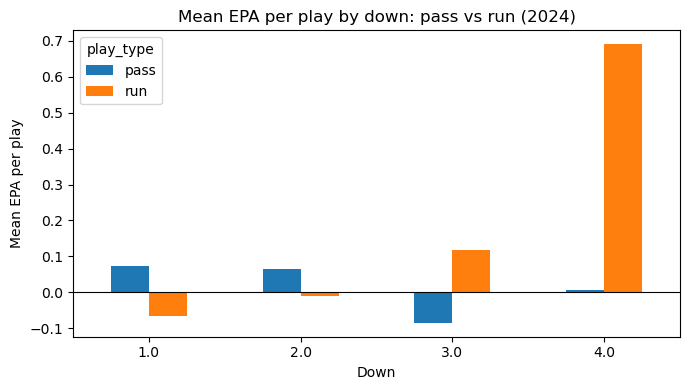

In [12]:
import matplotlib.pyplot as plt

by_down = plays[plays["down"].isin([1,2,3,4])].groupby(["down", "play_type"])["epa"].mean().unstack()
by_down.plot(kind="bar", figsize=(7,4))
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Mean EPA per play by down: pass vs run (2024)")
plt.xlabel("Down")
plt.ylabel("Mean EPA per play")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("epa_by_down.png", dpi = 150)
plt.show()